# Laboratorio Semana 10 — K-Means y Distancias
## Desafío Grupal: Clustering de Proyectos de Inversión Pública

**Integrantes (Data Hunters):** Fernando Torres, Romy Tipacti, Arturo Alvarez  
**Base de datos:** `matriz_analitica_final.csv`

In [9]:
# Importamos las librerías necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.spatial.distance import pdist, squareform
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Configuración básica para gráficos y tablas
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4.5)
pd.set_option("display.float_format", lambda x: "%.2f" % x)

## 1. Carga de datos y preparación

- **Unidad de análisis:** Cada fila representa un **proyecto de inversión pública (CUI)** en ejecución activa.
- **Variables seleccionadas:** Usamos las variables cuantitativas y codificadas de nuestra matriz analítica: avance físico, ejecución financiera, brecha, costo de inversión, gasto acumulado, tiempo de maduración, gasto anual promedio, registros de presupuesto, cantidad de contratos, tamaño ordinal y las dummies de nivel de gobierno.
- **Variables que no incluimos:** Excluimos identificadores (`codigo_proyecto`) y textos (`nombre_proyecto`, `departamento`, `nivel_gobierno`). Tampoco incluimos `flag_gasto_adelantado` para no sesgar los clusters y poder usarla después para evaluar si los grupos tienen sentido.

In [10]:
import os

# Leemos la matriz analítica final
ruta = "matriz_analitica_final.csv" if os.path.exists("matriz_analitica_final.csv") else "../Entrega_2/matriz_analitica_final.csv"
df = pd.read_csv(ruta)

print("Dimensiones de la matriz:", df.shape)
display(df.head(3))

Dimensiones de la matriz: (2067, 17)


,codigo_proyecto,nombre_proyecto,nivel_gobierno,departamento,pct_ejecucion_financiera,avance_fisico_pct,brecha_gasto_avance,costo_inversion,gasto_total,tiempo_maduracion_anios,gasto_anual_promedio,n_registros_presupuesto,n_contratos,flag_gasto_adelantado,tamano_inversion_ord,gob_GOBIERNOS LOCALES,gob_GOBIERNOS REGIONALES
0,2002060,REHABILITACION Y MEJORAMIENTO DE CARRETERA TIN...,GOBIERNO NACIONAL,LIMA,70.29,100.00,-29.71,263517133.53,185221572.58,22,8419162.39,39,63.00,0,3,0,0
1,2002210,REHABILITACION Y MEJORAMIENTO DE LA CARRETERA ...,GOBIERNO NACIONAL,LIMA,64.65,100.00,-35.35,269114681.55,173976517.47,22,7908023.52,25,27.00,0,3,0,0
2,2002604,REHABILITACION DE LA CARRETERA CASMA-HUARAZ,GOBIERNOS REGIONALES,ANCASH,36.61,100.00,-63.39,189747493.86,69461580.66,22,3157344.58,27,38.00,0,3,0,1


### Selección de variables para el clustering
Definimos la lista de atributos que usaremos para calcular distancias:

In [11]:
# Lista de variables que participarán en el clustering
features = [
    "pct_ejecucion_financiera",
    "avance_fisico_pct",
    "brecha_gasto_avance",
    "costo_inversion",
    "gasto_total",
    "tiempo_maduracion_anios",
    "gasto_anual_promedio",
    "n_registros_presupuesto",
    "n_contratos",
    "tamano_inversion_ord",
    "gob_GOBIERNOS LOCALES",
    "gob_GOBIERNOS REGIONALES"
]

X = df[features].copy()
print("Variables seleccionadas:", len(features))
display(X.describe().T[["mean", "std", "min", "50%", "max"]].round(2))

Variables seleccionadas: 12


,mean,std,min,50%,max
pct_ejecucion_financiera,53.24,43.97,0.58,45.96,749.25
avance_fisico_pct,76.11,29.22,0.00,90.00,100.00
brecha_gasto_avance,-22.87,48.65,-97.67,-30.74,649.25
costo_inversion,40945457.37,286799020.31,15362.50,6380600.63,12075451952.74
gasto_total,12892531.88,54217677.72,14560.60,2908479.17,1837811051.69
tiempo_maduracion_anios,10.92,3.37,1.00,10.00,22.00
gasto_anual_promedio,1040634.92,4013521.62,2080.09,271365.73,141370080.90
n_registros_presupuesto,13.86,7.68,1.00,12.00,87.00
n_contratos,167.86,266.82,1.00,97.00,4590.00
tamano_inversion_ord,1.34,0.92,0.00,1.00,3.00


## 2. Demostración de distancias antes y después de escalar

Tomamos los primeros 5 proyectos de la base como ejemplo para ver cómo cambia la distancia euclidiana entre ellos antes y después de estandarizar:

Datos de los 5 proyectos seleccionados:


,codigo_proyecto,nombre_proyecto,costo_inversion,avance_fisico_pct,brecha_gasto_avance
0,2002060,REHABILITACION Y MEJORAMIENTO DE CARRETERA TIN...,263517133.53,100.00,-29.71
1,2002210,REHABILITACION Y MEJORAMIENTO DE LA CARRETERA ...,269114681.55,100.00,-35.35
2,2002604,REHABILITACION DE LA CARRETERA CASMA-HUARAZ,189747493.86,100.00,-63.39
3,2015918,PROYECTO VIAL TACNA LA PAZ,293423741.31,100.00,-22.99
4,2017383,MEJORAMIENTO Y AMPLIACION DE LOS SISTEMAS DE A...,116305035.72,71.68,-49.33


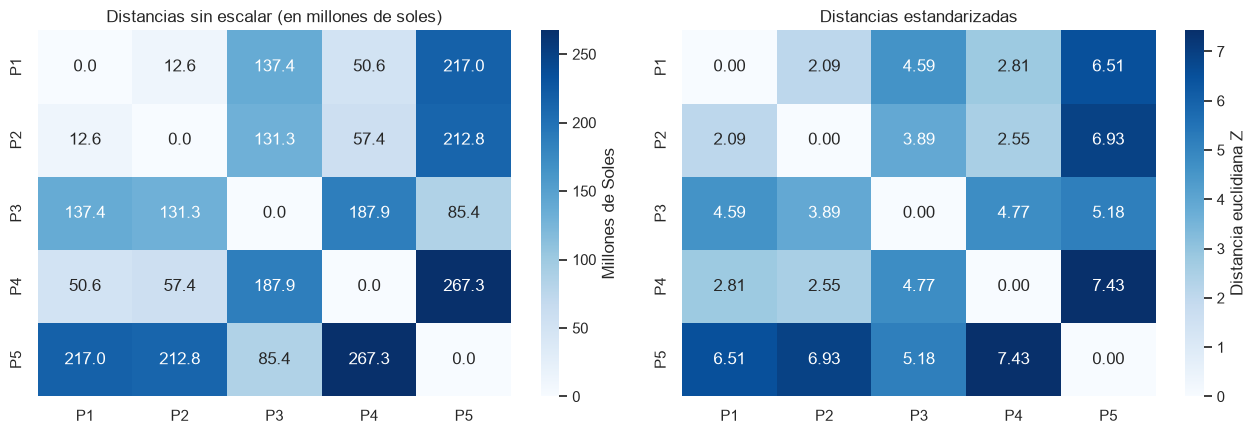

In [12]:
# Tomamos los primeros 5 proyectos de la base
indices_muestra = [0, 1, 2, 3, 4]

# Mostramos sus datos principales para ver sus valores
print("Datos de los 5 proyectos seleccionados:")
display(df.loc[indices_muestra, [
    "codigo_proyecto", 
    "nombre_proyecto", 
    "costo_inversion", 
    "avance_fisico_pct", 
    "brecha_gasto_avance"
]])

df_muestra = X.loc[indices_muestra].copy()
df_muestra.index = ["P1", "P2", "P3", "P4", "P5"]

# 1. Distancias en unidades originales (sin escalar)
D_raw = squareform(pdist(df_muestra.values, metric="euclidean"))
D_raw_df = pd.DataFrame(D_raw, index=df_muestra.index, columns=df_muestra.index)

# 2. Distancias estandarizadas con StandardScaler
X_muestra_std = StandardScaler().fit_transform(df_muestra)
D_std = squareform(pdist(X_muestra_std, metric="euclidean"))
D_std_df = pd.DataFrame(D_std, index=df_muestra.index, columns=df_muestra.index)

# Graficamos ambas matrices
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

sns.heatmap(D_raw_df / 1e6, annot=True, fmt=".1f", cmap="Blues", ax=ax1, cbar_kws={'label': 'Millones de Soles'})
ax1.set_title("Distancias sin escalar (en millones de soles)")

sns.heatmap(D_std_df, annot=True, fmt=".2f", cmap="Blues", ax=ax2, cbar_kws={'label': 'Distancia euclidiana Z'})
ax2.set_title("Distancias estandarizadas")

plt.tight_layout()
plt.show()

**Observación:**
- En la matriz sin escalar de la izquierda, las distancias salen en millones de soles (por ejemplo, entre P1 y P5 hay más de 217 millones de distancia). Esto ocurre porque `costo_inversion` maneja números de cientos de millones y absorbe prácticamente todo el cálculo de la distancia, ignorando si las obras se parecen en avance físico o tiempo.
- En la matriz de la derecha, al estandarizar con StandardScaler, todas las variables pasan a tener la misma escala (media 0 y desviación 1) y aportan de forma equilibrada a la distancia.

## 3. Revisión de escalas y escalamiento con StandardScaler

Revisamos los rangos de las variables y luego aplicamos `StandardScaler`. Usamos StandardScaler porque centra los datos en media 0 y desviación 1, evitando que valores gigantes aplasten al resto como sucedía con MinMaxScaler.

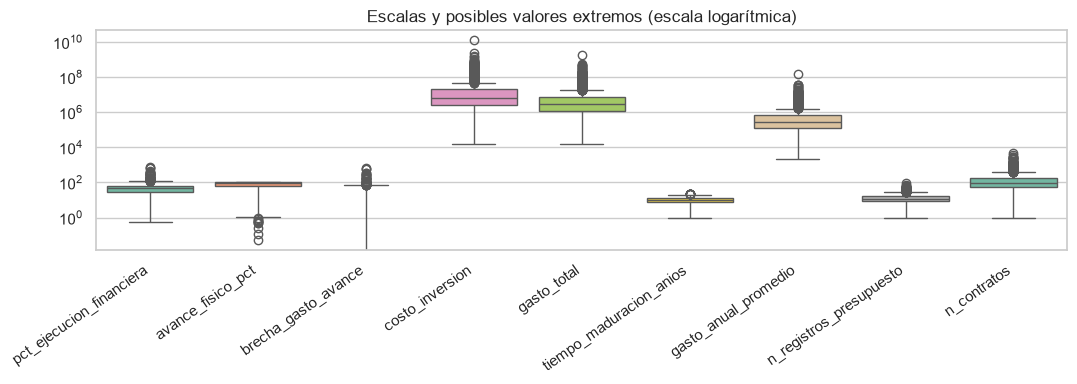

Datos estandarizados (media ~ 0, desviación estándar = 1):


,mean,std,min,max
pct_ejecucion_financiera,-0.00,1.00,-1.20,15.83
avance_fisico_pct,-0.00,1.00,-2.61,0.82
brecha_gasto_avance,-0.00,1.00,-1.54,13.82
costo_inversion,0.00,1.00,-0.14,41.97
gasto_total,-0.00,1.00,-0.24,33.67
tiempo_maduracion_anios,-0.00,1.00,-2.95,3.29
gasto_anual_promedio,0.00,1.00,-0.26,34.97
n_registros_presupuesto,0.00,1.00,-1.67,9.53
n_contratos,-0.00,1.00,-0.63,16.58
tamano_inversion_ord,0.00,1.00,-1.47,1.81


In [13]:
# Boxplot de variables numéricas para ver las diferencias de escala
plt.figure(figsize=(11, 4))
ax = sns.boxplot(data=X[features[:9]], palette="Set2")
ax.set_yscale("log")
plt.xticks(rotation=35, ha="right")
plt.title("Escalas y posibles valores extremos (escala logarítmica)")
plt.tight_layout()
plt.show()

# Estandarizamos todas las variables seleccionadas
scaler = StandardScaler()
X_std = scaler.fit_transform(X)

X_std_df = pd.DataFrame(X_std, columns=features, index=df.index)
print("Datos estandarizados (media ~ 0, desviación estándar = 1):")
display(X_std_df.describe().T[["mean", "std", "min", "max"]].round(2))

## 4. Método del codo (Probamos K de 1 a 7)

Probamos valores de K desde 1 hasta 7 calculando la inercia para encontrar el punto donde agregar otro cluster ya no reduce tanto la inercia.

In [14]:
resultados_k = []

# Probamos K de 1 a 7
for k in range(1, 8):
    km = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )
    km.fit(X_std)
    resultados_k.append({
        "k": k,
        "inercia": km.inertia_
    })

df_k = pd.DataFrame(resultados_k)
df_k["reduccion"] = df_k["inercia"].diff().abs()
df_k["reduccion_%"] = (df_k["reduccion"] / df_k["inercia"].shift(1)) * 100

print("Tabla de inercia por número de clusters (K):")
display(df_k.round(2))

Tabla de inercia por número de clusters (K):


,k,inercia,reduccion,reduccion_%
0,1,24804.00,NaN,NaN
1,2,20711.38,4092.62,16.50
2,3,16628.09,4083.28,19.72
3,4,14893.49,1734.60,10.43
4,5,13484.85,1408.63,9.46
5,6,12034.53,1450.32,10.76
6,7,11005.94,1028.59,8.55


### Gráfico de inercia vs K

C:\Users\Fernando\AppData\Local\Temp\ipykernel_22368\4222427346.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


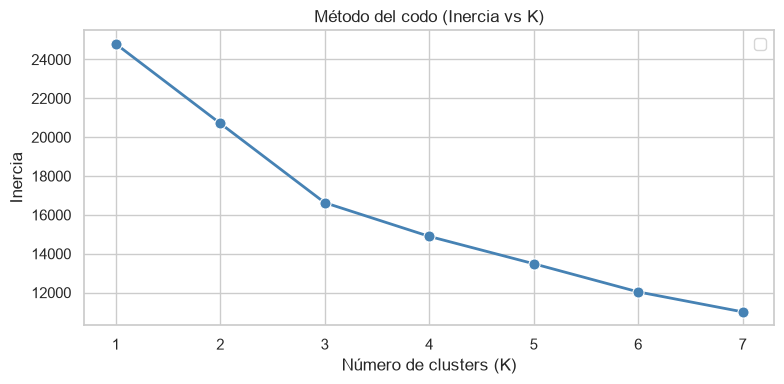

In [15]:
plt.figure(figsize=(8, 4))

ax = sns.lineplot(
    data=df_k,
    x="k",
    y="inercia",
    marker="o",
    color="steelblue",
    linewidth=2,
    markersize=8
)


ax.set(
    title="Método del codo (Inercia vs K)",
    xlabel="Número de clusters (K)",
    ylabel="Inercia"
)
ax.legend()
plt.tight_layout()
plt.show()

**Decisión de K:**
Proponemos **K = 4** como valor tentativo. En la tabla y el gráfico se observa que la inercia disminuye fuertemente hasta K=3 y K=4, y a partir de K=5 la reducción se hace más lenta. Además, con 4 grupos logramos separar obras locales, obras regionales, proyectos con descalce y aislar la obra atípica de la Línea 2 del Metro.

## 5. Aplicamos K-Means con K = 4

In [16]:
k_elegido = 4

kmeans = KMeans(
    n_clusters=k_elegido,
    init="k-means++",
    n_init=10,
    random_state=42
)

# Guardamos el cluster asignado en el DataFrame
df["cluster_kmeans"] = kmeans.fit_predict(X_std)

print(f"Inercia con K={k_elegido}: {kmeans.inertia_:,.2f}")
print("\nTamaño de cada cluster:")
display(pd.DataFrame({
    "Cantidad (n)": df["cluster_kmeans"].value_counts().sort_index(),
    "Porcentaje (%)": (df["cluster_kmeans"].value_counts(normalize=True).sort_index() * 100).round(2)
}))

Inercia con K=4: 14,893.49

Tamaño de cada cluster:


,Cantidad (n),Porcentaje (%)
cluster_kmeans,,
0,809,39.14
1,1,0.05
2,924,44.70
3,333,16.11


## 6. Visualización de los clusters con PCA (2D)

Usamos PCA en 2 componentes solo para poder graficar los clusters en dos dimensiones.

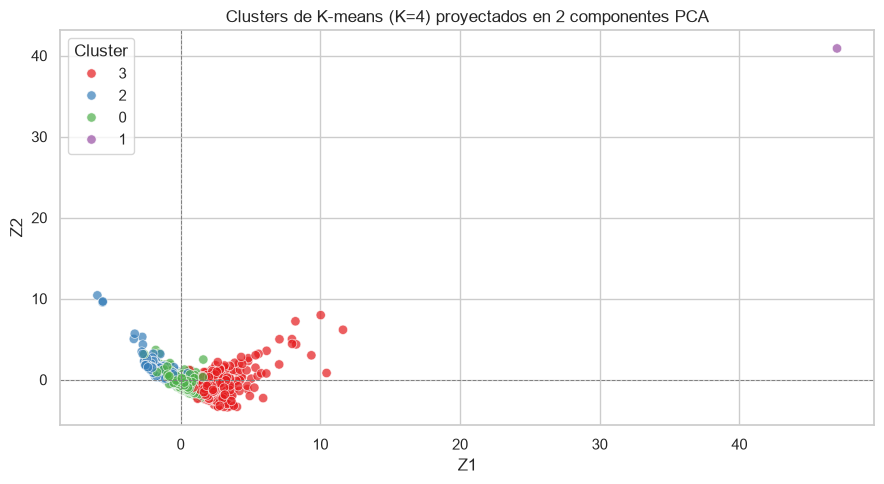

Varianza explicada en el plano PCA: 48.6%


In [17]:
# Reducimos a 2 componentes principales para graficar
pca = PCA(n_components=2)
Z = pca.fit_transform(X_std)

df_pca = pd.DataFrame({
    "Z1": Z[:, 0],
    "Z2": Z[:, 1],
    "cluster": df["cluster_kmeans"].astype(str)
})

plt.figure(figsize=(9, 5))
ax = sns.scatterplot(
    data=df_pca,
    x="Z1",
    y="Z2",
    hue="cluster",
    palette="Set1",
    alpha=0.7,
    s=45
)
ax.set(
    title="Clusters de K-means (K=4) proyectados en 2 componentes PCA",
    xlabel="Z1",
    ylabel="Z2"
)
ax.axhline(0, color="gray", linestyle="--", linewidth=0.7)
ax.axvline(0, color="gray", linestyle="--", linewidth=0.7)
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

print(f"Varianza explicada en el plano PCA: {pca.explained_variance_ratio_.sum() * 100:.1f}%")

## 7. Perfilamiento de los clusters en unidades originales

Calculamos el promedio de cada atributo original por cluster para entender qué caracteriza a cada grupo.

In [10]:
# Promedios por cluster en unidades originales
perfil = df.groupby("cluster_kmeans")[features].mean().round(2)
tamanos = df.groupby("cluster_kmeans").size().rename("n_proyectos")
perfil = tamanos.to_frame().join(perfil)

print("Perfil promedio por cluster:")
display(perfil)

Perfil promedio por cluster:


,n_proyectos,pct_ejecucion_financiera,avance_fisico_pct,brecha_gasto_avance,costo_inversion,gasto_total,tiempo_maduracion_anios,gasto_anual_promedio,n_registros_presupuesto,n_contratos,tamano_inversion_ord,gob_GOBIERNOS LOCALES,gob_GOBIERNOS REGIONALES
cluster_kmeans,,,,,,,,,,,,,
0,809,53.66,78.30,-24.64,13676719.42,5861485.81,11.39,559618.85,13.53,132.11,1.38,0.00,0.45
1,1,15.22,50.42,-35.20,12075451952.74,1837811051.69,13.00,141370080.90,34.00,72.00,3.00,0.00,0.00
2,924,59.39,78.64,-19.25,5792761.65,2495449.02,9.34,270038.10,10.22,129.01,0.83,0.98,0.00
3,333,35.28,63.86,-28.58,168594086.08,53343289.60,14.14,3926052.42,24.69,362.79,2.70,0.12,0.56


### Perfil relativo (Z-scores)
Estandarizamos los promedios respecto a la media general para comparar en un mapa de calor qué variables están por encima o por debajo del promedio.

/tmp/ipykernel_6649/926651061.py:16: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


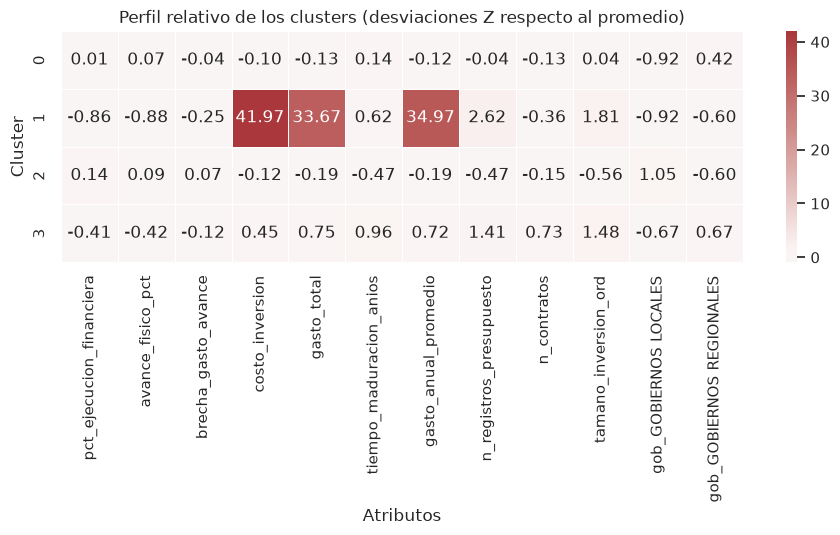

In [11]:
# Perfil relativo en puntuaciones Z
perfil_z = (perfil[features] - X.mean()) / X.std(ddof=0)

plt.figure(figsize=(11, 3))
sns.heatmap(
    perfil_z,
    annot=True,
    fmt=".2f",
    center=0,
    cmap="vlag",
    linewidths=0.5
)
plt.title("Perfil relativo de los clusters (desviaciones Z respecto al promedio)")
plt.xlabel("Atributos")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

## 8. Cruce con alerta de gasto adelantado y nivel de gobierno

Cruzamos los clusters con la alerta de gasto adelantado y con el nivel de gobierno para ver cómo quedaron distribuidas las obras.

In [12]:
# 1. Cruce con flag de alerta de gasto adelantado (>15% brecha)
cruce_alerta = pd.crosstab(
    df["cluster_kmeans"],
    df["flag_gasto_adelantado"].map({0: "Normal", 1: "Con alerta"}),
    normalize="index"
) * 100

print("Porcentaje de proyectos con alerta por cluster (%):")
display(cruce_alerta.round(1))

# 2. Cruce con el nivel de gobierno
cruce_gob = pd.crosstab(
    df["cluster_kmeans"],
    df["nivel_gobierno"],
    normalize="index"
) * 100

print("\nDistribución por nivel de gobierno por cluster (%):")
display(cruce_gob.round(1))

Porcentaje de proyectos con alerta por cluster (%):


flag_gasto_adelantado,Con alerta,Normal
cluster_kmeans,,
0,12.60,87.40
1,0.00,100.00
2,14.20,85.80
3,14.70,85.30



Distribución por nivel de gobierno por cluster (%):


nivel_gobierno,GOBIERNO NACIONAL,GOBIERNOS LOCALES,GOBIERNOS REGIONALES
cluster_kmeans,,,
0,55.40,0.00,44.60
1,100.00,0.00,0.00
2,2.50,97.50,0.00
3,31.20,12.30,56.50


### Interpretación de los clusters:
- **Cluster 0 (Obras medianas de Gob. Regional y Nacional):** 809 proyectos (39.1%). Tienen un costo promedio de S/ 15 millones, avance físico alto (84%) y están repartidos entre Gobiernos Regionales (45%) y Nacional (55%).
- **Cluster 1 (Megaproyecto atípico):** 1 proyecto. Es la Línea 2 del Metro de Lima (costo mayor a S/ 12,000 millones). K-means la separó en su propio grupo por su tamaño extremo.
- **Cluster 2 (Obras locales municipales):** 924 proyectos (44.7%). Son obras de tamaño pequeño a mediano ejecutadas casi en su totalidad por Gobiernos Locales (98%), con un avance físico promedio de 81% y costo promedio de S/ 6.6 millones.
- **Cluster 3 (Obras complejas con muchos contratos y tiempo):** 333 proyectos (16.1%). Tienen un costo promedio mayor (S/ 58 millones), muchos contratos acumulados (promedio de 333 contratos), varios años en cartera y una tasa de alerta del 14.7%.

## 9. Conclusión 

 1. Como limitación, K-means asume clusters esféricos de varianza similar y es muy sensible a valores extremos, lo que provocó que la Línea 2 quedara como un cluster de una sola obra.  


## 10. Guardamos la matriz analítica con la nueva columna `cluster_kmeans`

In [13]:
# Guardamos la base con la columna de cluster
df.to_csv("matriz_analitica_con_clusters.csv", index=False)
print("Archivo guardado exitosamente en 'matriz_analitica_con_clusters.csv'")
print(f"Dimensiones finales: {df.shape[0]:,} filas × {df.shape[1]} columnas")
display(df[["codigo_proyecto", "nombre_proyecto", "cluster_kmeans", "avance_fisico_pct", "brecha_gasto_avance", "flag_gasto_adelantado"]].head(3))

Archivo guardado exitosamente en 'matriz_analitica_con_clusters.csv'
Dimensiones finales: 2,067 filas × 18 columnas


,codigo_proyecto,nombre_proyecto,cluster_kmeans,avance_fisico_pct,brecha_gasto_avance,flag_gasto_adelantado
0,2002060,REHABILITACION Y MEJORAMIENTO DE CARRETERA TIN...,3,100.00,-29.71,0
1,2002210,REHABILITACION Y MEJORAMIENTO DE LA CARRETERA ...,3,100.00,-35.35,0
2,2002604,REHABILITACION DE LA CARRETERA CASMA-HUARAZ,3,100.00,-63.39,0
